In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


Input shape: (300, 2)
Class counts: [150 150]


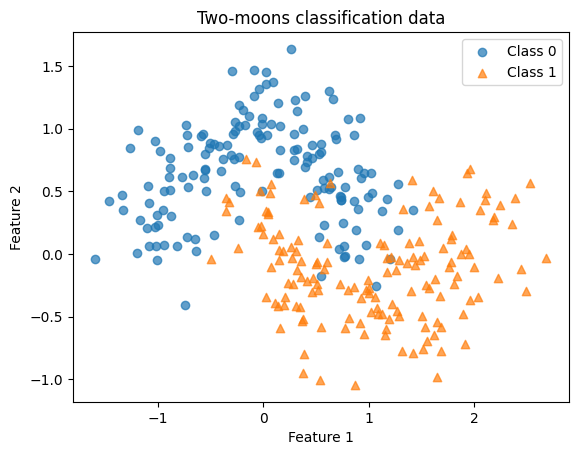

In [ ]:
X, y = make_moons(n_samples=300, noise=0.25,
random_state=42)
print("Input shape:", X.shape)
print("Class counts:", np.bincount(y))
for label, marker in [(0, "o"), (1, "^")]:
  plt.scatter(X[y == label, 0], X[y == label, 1],
marker=marker, label=f"Class {label}",
alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-moons classification data")
plt.legend()
plt.show()

In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(
X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
X_dev, y_dev, test_size=0.25, stratify=y_dev,
random_state=42)
print("Train / validation / test rows:",
len(y_train), len(y_val), len(y_test))

Train / validation / test rows: 180 60 60


In [ ]:
stump = DecisionTreeClassifier(max_depth=1,
random_state=42)
stump.fit(X_train, y_train)
stump_train = accuracy_score(
y_train, stump.predict(X_train))
stump_val = accuracy_score(y_val, stump.predict(X_val))
print("Training accuracy:", round(stump_train, 3))
print("Validation accuracy:", round(stump_val, 3))

Training accuracy: 0.844
Validation accuracy: 0.783


In [ ]:
ada = AdaBoostClassifier(
estimator=DecisionTreeClassifier(max_depth=1),
n_estimators=50, learning_rate=0.5,
random_state=42)
ada.fit(X_train, y_train)
ada_val_pred = ada.predict(X_val)
ada_train = accuracy_score(y_train, ada.predict(X_train))
ada_val = accuracy_score(y_val, ada_val_pred)
print("Training accuracy:", round(ada_train, 3))
print("Validation accuracy:", round(ada_val, 3))
print("Learners fitted:", len(ada.estimators_))

Training accuracy: 0.972
Validation accuracy: 0.883
Learners fitted: 50


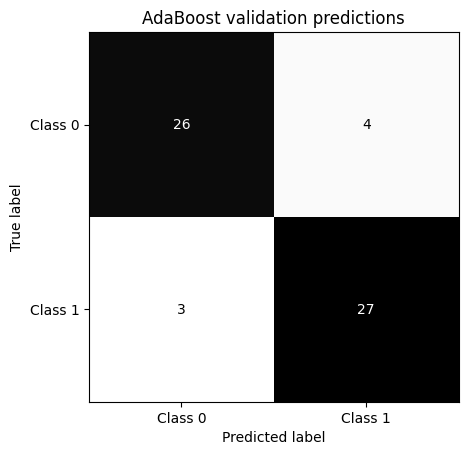

In [ ]:
ConfusionMatrixDisplay.from_predictions(
y_val, ada_val_pred, labels=[0, 1],
display_labels=["Class 0", "Class 1"],
cmap="Greys", colorbar=False)
plt.title("AdaBoost validation predictions")
plt.show()

In [ ]:
counts = [5, 20, 50, 100]
train_scores = []
val_scores = []
for n in counts:
  candidate = AdaBoostClassifier(
  estimator=DecisionTreeClassifier(max_depth=1),
  n_estimators=n, learning_rate=0.5,
  random_state=42)
  candidate.fit(X_train, y_train)
  train_scores.append(accuracy_score(
  y_train, candidate.predict(X_train)))
  val_scores.append(accuracy_score(
  y_val, candidate.predict(X_val)))
  print(n, round(train_scores[-1], 3),
  round(val_scores[-1], 3))
best_n = counts[int(np.argmax(val_scores))]
print("Chosen number of learners:", best_n)

5 0.906 0.833
20 0.928 0.833
50 0.972 0.883
100 0.978 0.883
Chosen number of learners: 50


In [ ]:
gradient = GradientBoostingClassifier(
n_estimators=50, learning_rate=0.1,
max_depth=2, random_state=42)
gradient.fit(X_train, y_train)
gradient_train = accuracy_score(
y_train, gradient.predict(X_train))
gradient_val = accuracy_score(
y_val, gradient.predict(X_val))
print("Training accuracy:", round(gradient_train, 3))
print("Validation accuracy:", round(gradient_val, 3))

Training accuracy: 0.978
Validation accuracy: 0.883


In [ ]:
histogram = HistGradientBoostingClassifier(
max_iter=50, learning_rate=0.1, max_depth=2,
min_samples_leaf=10, early_stopping=False,
random_state=42)
histogram.fit(X_train, y_train)
hist_train = accuracy_score(
y_train, histogram.predict(X_train))
hist_val = accuracy_score(
y_val, histogram.predict(X_val))
print("Training accuracy:", round(hist_train, 3))
print("Validation accuracy:", round(hist_val, 3))
print("Iterations fitted:", histogram.n_iter_)

Training accuracy: 0.961
Validation accuracy: 0.867
Iterations fitted: 50


Stump 0.783
AdaBoost 0.883
Gradient 0.883
Histogram 0.867


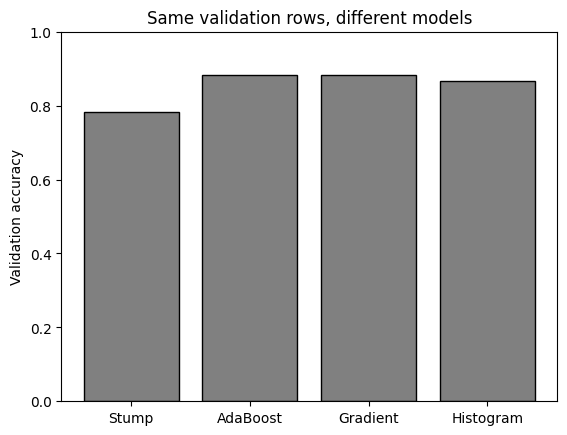

Selected configuration: AdaBoost


In [ ]:
ada_selected = AdaBoostClassifier(
estimator=DecisionTreeClassifier(max_depth=1),
n_estimators=best_n, learning_rate=0.5,
random_state=42)
ada_selected.fit(X_train, y_train)
models = {"Stump": stump, "AdaBoost": ada_selected,
"Gradient": gradient, "Histogram": histogram}
scores = {}
for name, model in models.items():
  scores[name] = accuracy_score(
  y_val, model.predict(X_val))
  print(name, round(scores[name], 3))
plt.bar(list(scores.keys()), list(scores.values()),
color="gray", edgecolor="black")
plt.ylim(0, 1)
plt.ylabel("Validation accuracy")
plt.title("Same validation rows, different models")
plt.show()
best_name = max(scores, key=scores.get)
print("Selected configuration:", best_name)

Selected model: AdaBoost
Test accuracy: 0.833
Test mistakes: 10 out of 60


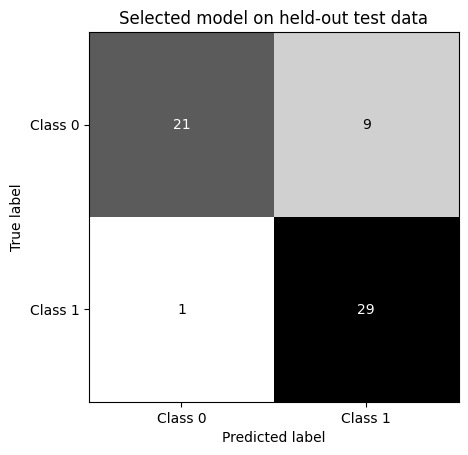

In [ ]:
final_model = models[best_name]
final_model.fit(X_dev, y_dev)
test_pred = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_pred)
test_mistakes = np.sum(y_test != test_pred)
print("Selected model:", best_name)
print("Test accuracy:", round(test_accuracy, 3))
print("Test mistakes:", test_mistakes, "out of", len(y_test))
ConfusionMatrixDisplay.from_predictions(
y_test, test_pred, labels=[0, 1],
display_labels=["Class 0", "Class 1"],
cmap="Greys", colorbar=False)
plt.title("Selected model on held-out test data")
plt.show()

Rate: 0.1 Validation: 0.833
Rate: 0.5 Validation: 0.883
Rate: 1.0 Validation: 0.9


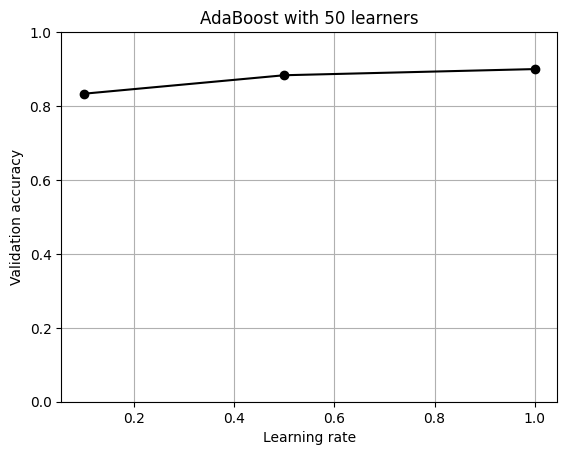

In [ ]:
rates = [0.1, 0.5, 1.0]
rate_scores = []
for rate in rates:
  rate_model = AdaBoostClassifier(
  estimator=DecisionTreeClassifier(max_depth=1),
  n_estimators=50, learning_rate=rate,
  random_state=42)
  rate_model.fit(X_train, y_train)
  score = accuracy_score(
  y_val, rate_model.predict(X_val))
  rate_scores.append(score)
  print("Rate:", rate, "Validation:", round(score, 3))
plt.plot(rates, rate_scores, marker="o", color="black")
plt.xlabel("Learning rate")
plt.ylabel("Validation accuracy")
plt.ylim(0, 1)
plt.title("AdaBoost with 50 learners")
plt.grid(True)
plt.show()

In [ ]:
%pip install -q xgboost

In [ ]:
from xgboost import XGBClassifier
xgb = XGBClassifier(
n_estimators=50, max_depth=2, learning_rate=0.1,
objective="binary:logistic", eval_metric="logloss",
random_state=42, n_jobs=1)
xgb.fit(X_train, y_train)
xgb_score = accuracy_score(y_val, xgb.predict(X_val))
print("XGBoost validation accuracy:", round(xgb_score, 3))
print("Earlier validation scores:", scores)

XGBoost validation accuracy: 0.883
Earlier validation scores: {'Stump': 0.7833333333333333, 'AdaBoost': 0.8833333333333333, 'Gradient': 0.8833333333333333, 'Histogram': 0.8666666666666667}
